In [8]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

# Re-load and clean (notebooks are independent)
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(url)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
df.drop('customerID', axis=1, inplace=True)
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

X = df.drop('Churn', axis=1)
y = df['Churn']

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

print("Numeric columns:", num_cols)
print("Categorical columns:", cat_cols)

# Preprocessing pipelines
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("\nTrain size:", X_train.shape)
print("Test size:", X_test.shape)

Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Train size: (5634, 19)
Test size: (1409, 19)


C:\Users\chand\AppData\Local\Temp\ipykernel_18688\337356597.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import f1_score, roc_auc_score, classification_report

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=500),
    'Random Forest':       RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=42),
}

results = {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    results[name] = {
        'F1 (churn)':     round(f1_score(y_test, y_pred), 3),
        'Recall (churn)': round(f1_score(y_test, y_pred, pos_label=1, average='binary'), 3),
        'ROC-AUC':        round(roc_auc_score(y_test, y_prob), 3)
    }

results_df = pd.DataFrame(results).T
print(results_df.sort_values('F1 (churn)', ascending=False))

                     F1 (churn)  Recall (churn)  ROC-AUC
Logistic Regression       0.614           0.614    0.841
Gradient Boosting         0.589           0.589    0.843
Random Forest             0.586           0.586    0.821


In [10]:
from sklearn.model_selection import GridSearchCV

best_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', GradientBoostingClassifier(random_state=42))
])

param_grid = {
    'model__n_estimators':  [100, 200],
    'model__max_depth':     [3, 5],
    'model__learning_rate': [0.05, 0.1],
}

gs = GridSearchCV(best_pipe, param_grid, cv=5, scoring='f1', n_jobs=-1)
gs.fit(X_train, y_train)

print('Best params:', gs.best_params_)
print('Best CV F1: ', round(gs.best_score_, 3))

final_pred = gs.predict(X_test)
from sklearn.metrics import classification_report
print('\nFinal Test Results:')
print(classification_report(y_test, final_pred, target_names=['No Churn', 'Churn']))

Best params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}
Best CV F1:  0.586

Final Test Results:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.66      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



Best threshold: 0.343
Best F1 at that threshold: 0.631

Results with tuned threshold:
              precision    recall  f1-score   support

    No Churn       0.89      0.80      0.84      1035
       Churn       0.56      0.72      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.76      0.74      1409
weighted avg       0.80      0.78      0.78      1409



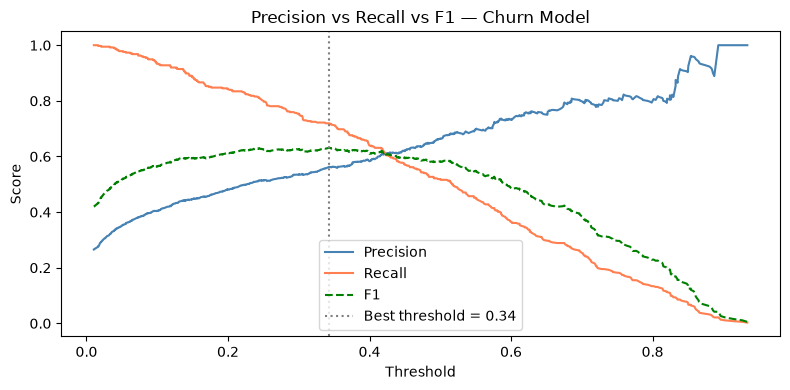

In [11]:
from sklearn.metrics import precision_recall_curve, f1_score
import matplotlib.pyplot as plt
import numpy as np

# Get churn probabilities
y_prob = gs.predict_proba(X_test)[:, 1]

# Try every threshold
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
print(f'Best threshold: {best_threshold:.3f}')
print(f'Best F1 at that threshold: {f1_scores[best_idx]:.3f}')

# Apply the new threshold
y_pred_tuned = (y_prob >= best_threshold).astype(int)
print('\nResults with tuned threshold:')
print(classification_report(y_test, y_pred_tuned, target_names=['No Churn', 'Churn']))

# Plot Precision-Recall tradeoff
plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], label='Precision', color='steelblue')
plt.plot(thresholds, recalls[:-1], label='Recall', color='coral')
plt.plot(thresholds, f1_scores[:-1], label='F1', color='green', linestyle='--')
plt.axvline(best_threshold, color='gray', linestyle=':', label=f'Best threshold = {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision vs Recall vs F1 — Churn Model')
plt.legend()
plt.tight_layout()
plt.savefig('threshold_plot.png', dpi=150)
plt.show()

                       feature  importance
       Contract_Month-to-month    0.377225
                        tenure    0.135144
                  TotalCharges    0.095861
   InternetService_Fiber optic    0.087816
                MonthlyCharges    0.074357
             OnlineSecurity_No    0.066677
                TechSupport_No    0.046248
PaymentMethod_Electronic check    0.040535
              MultipleLines_No    0.011376
           PaperlessBilling_No    0.011239


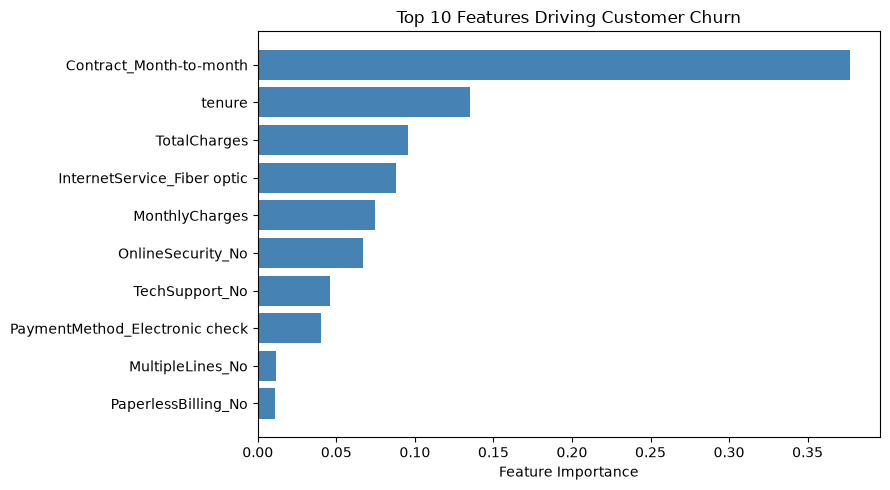

Model saved to: e:\AI&ML Course\churn-prediction\models\best_model.pkl
File size: 276621 bytes


In [15]:
import joblib
import os

# Get feature names after encoding
cat_feature_names = (gs.best_estimator_
    .named_steps['prep']
    .named_transformers_['cat']
    .named_steps['encoder']
    .get_feature_names_out(cat_cols))

all_features = num_cols + list(cat_feature_names)
importances = gs.best_estimator_.named_steps['model'].feature_importances_

feat_df = pd.DataFrame({'feature': all_features, 'importance': importances})
feat_df = feat_df.sort_values('importance', ascending=False).head(10)

print(feat_df.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(feat_df['feature'][::-1], feat_df['importance'][::-1], color='steelblue')
plt.xlabel('Feature Importance')
plt.title('Top 10 Features Driving Customer Churn')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# Save the model
project_root = os.path.dirname(os.getcwd())
model_path = os.path.join(project_root, 'models', 'best_model.pkl')

os.makedirs(os.path.dirname(model_path), exist_ok=True)
joblib.dump(gs.best_estimator_, model_path)

# Verify
size = os.path.getsize(model_path)
print(f'Model saved to: {model_path}')
print(f'File size: {size} bytes')
